Dataset Seçim Kontrolü
1.  Dataset ne hakkında?

1912 yılındaki Titanic faciasında yer alan yolcuların demografik, bilet ve seyahat bilgilerini ve hayatta kalma durumlarını içerir.

2.  Kaç satır ve sütun var?

Standart eğitim setinde 891 satır ve 12 sütun bulunmaktadır (Kodda PassengerId indekse alındığı için veri çerçevesi 891 satır, 11 sütun olarak işlenmektedir)

3.  Target var mı?

Target Survived değişkenidir (0: Hayatta kalamadı, 1: Hayatta kaldı).

4.  Problem classification mı, regression mı, başka bir tür mü?

İkili sınıflandırma (Binary Classification) problemidir.

5.  Eksik değer var mı?

Evet. Age, Cabin ve Embarked sütunlarında eksik değerler bulunmaktadır.

6.  Kişisel / hassas veri içeriyor mu?

Kişisel veri içermektedir fakat tarihi ve açık kaynaklı bir veri setidir.

7.  Kaynağı güvenilir ve belli mi?

Evet, veri seti Kaggle platformunda yer alan resmi ve doğrulanmış Titanic yarışmasına aittir: Kaggle - Titanic: Machine Learning from Disaster

8.  Lisans / kullanım koşulu uygun mu?

Evet. Kamuya açık, eğitim ve araştırma amaçlı kullanıma tamamen uygundur.

9.  Boyutu başlangıç seviyesi için yönetilebilir mi?

Evet. Boyutu 1 MB'ın altındadır, CPU ve Colab ortamında hızlıca işlenebilir.

10.  Bu haftanın öğrenme hedefine gerçekten uygun mu?

Kategorik, sayısal ve hedef değişken dengesi barındırdığı için dağılım, aykırı değer analizi ve görselleştirme hedeflerine birebir uygundur.

1-KURULUM VE VERİ YÜKLEME

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Grafiklerin düzgün görüntülenmesi ve genel stili sağlar
sns.set_theme(style = "whitegrid")
plt.rcParams["figure.figsize"] = (10,6)

import pandas as pd


dataset = pd.read_csv("train.csv", index_col="PassengerId")

print("Titanic Verisi Başarıyla Yüklendi:")
display(dataset.head())



print("Satır ve Sütun Sayısı:", dataset.shape)

Titanic Verisi Başarıyla Yüklendi:


,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Satır ve Sütun Sayısı: (891, 11)


2- Hedef Değişken (Survived) Dağılımı ve Sınıf Dengesi - Bar Chart

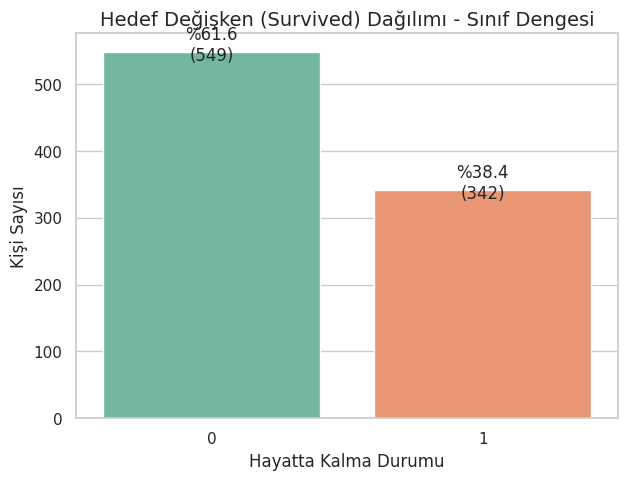

In [ ]:
plt.figure(figsize=(7,5))
ax = sns.countplot(data=dataset, x="Survived", palette="Set2", hue="Survived", legend=False)
plt.title("Hedef Değişken (Survived) Dağılımı - Sınıf Dengesi", fontsize=14)
plt.xlabel("Hayatta Kalma Durumu")
plt.ylabel("Kişi Sayısı")

# Barların üzerine oranları ve kişi sayılarını yazdırma
total = len(dataset)
for p in ax.patches:
  height =p.get_height()
  percantege = f"%{100 * height / total:.1f}\n({int(height)})"
  ax.annotate(percantege, (p.get_x() + p.get_width() / 2, height), ha="center", va="center", xytext=(0, 5), textcoords="offset points")

plt.show()


# ----------------------------------------------------------------------
# -RAPOR-
# Bu grafik bize
# --> Veri setinde belirgin bir sınıf dengesizliği olduğunu,
# --> Yolcuların yaklaşık %61.6'sının (549 kişi) hayatını kaybettiğini, yalnızca %38.4'ünün (342 kişi) hayatta kaldığını
# anlatıyor.
#
# -KONTROL SORUSU-
# Bu soruyu cevaplamak için neden bu grafik türünü seçtin?
# İkili sınıflandırma problemlerinde modelleme öncesi hedef değişkenin
# sınıf dengesini net ve oranlı görmek için Bar Chart en doğru yöntemdir.

3- Bilet Sınıfı (Pclass) ve Cinsiyet (Sex) Kırılımında Hayatta Kalma (Bar Chart)

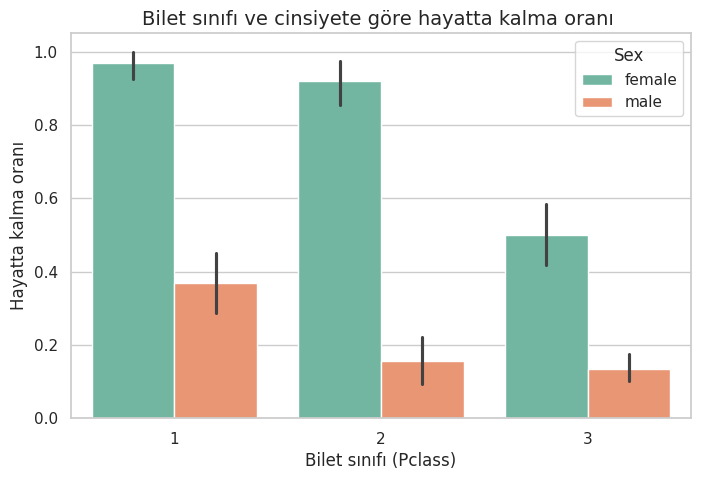

In [ ]:
plt.figure(figsize=(8,5))
sns.barplot(data=dataset, x="Pclass", y="Survived", hue="Sex", palette="Set2")
plt.title("Bilet sınıfı ve cinsiyete göre hayatta kalma oranı ",fontsize=14)
plt.xlabel("Bilet sınıfı (Pclass)")
plt.ylabel("Hayatta kalma oranı")
plt.show()

# ----------------------------------------------------------------------
# -RAPOR-
# Bu grafik bize
# -->Tüm bilet sınıflarında kadın yolcuların hayatta kalma oranı erkeklere göre çok daha yüksek olduğunu,
# -->1. sınıf yolcuların hayatta kalma ihtimali en yüksekken, 3. sınıfta bu oranın düşmekte olduğunu,
# -->Yolcunun sınıfı kurtulma şansında doğrudan belirleyici olduğunu
# anlatıyor

# -KONTROL SORUSU-
# Bu soruyu cevaplamak için neden bu grafik türünü seçtin?
# Kategorik değişkenlerin (Pclass, Sex) ikili hedef değişken (Survived) üzerindeki etkisini ve grup bazlı
#karşılaştırmayı en net gösteren yöntem Bar Chart olduğu için.


4- Ham Yaş (Age) ve Bilet Ücreti (Fare) Dağılımları (Histogram & KDE)

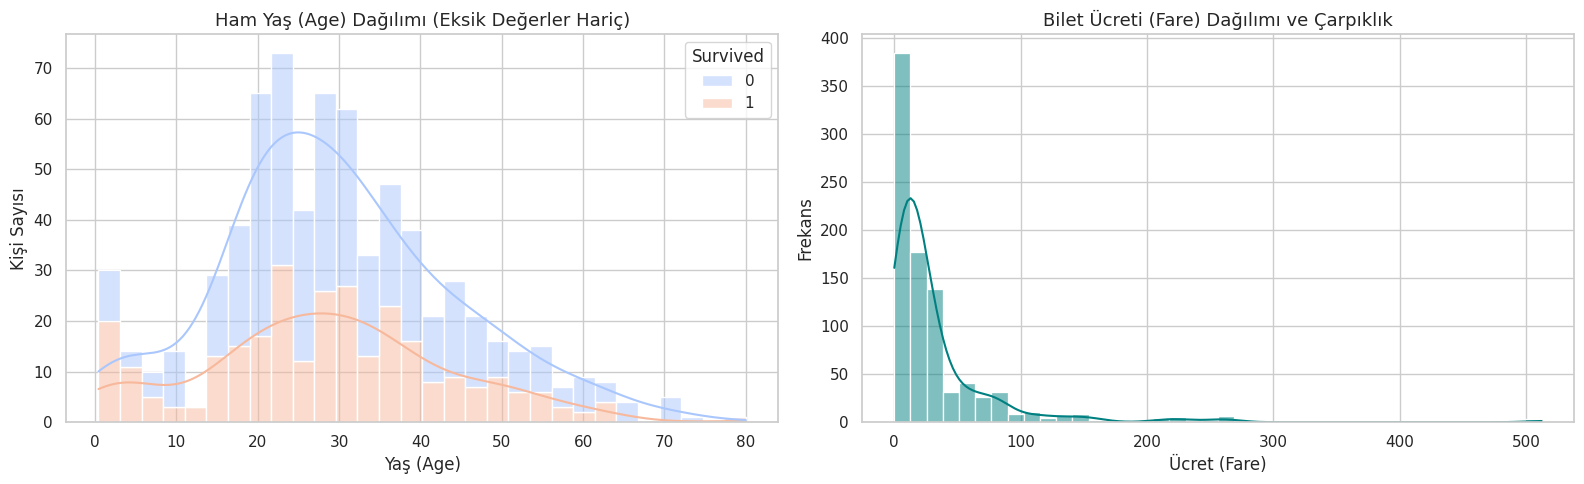

In [ ]:
fig, axes =plt.subplots(1,2, figsize=(16,5))

#Ham Yaş Dağılımı (Eksikler Doldurulmadan Önce)
sns.histplot(
    data=dataset.dropna(subset=["Age"]),
    x="Age",
    hue="Survived",
    multiple="stack",
    kde=True,
    palette="coolwarm",
    bins=30,
    ax=axes[0]
)
axes[0].set_title("Ham Yaş (Age) Dağılımı (Eksik Değerler Hariç)", fontsize=13)
axes[0].set_xlabel("Yaş (Age)")
axes[0].set_ylabel("Kişi Sayısı")


#Ücret Dağılımı (Sağa Çarpıklık Var)
sns.histplot(
    data=dataset,
    x="Fare",
    kde=True,
    color="teal",
    bins=40,
    ax=axes[1]
)
axes[1].set_title("Bilet Ücreti (Fare) Dağılımı ve Çarpıklık", fontsize=13)
axes[1].set_xlabel("Ücret (Fare)")
axes[1].set_ylabel("Frekans")

plt.tight_layout()
plt.show()
# ----------------------------------------------------------------------
# -RAPOR-
# Bu grafikler bize:
# --> Doğal yaş dağılımı 177 eksik değer hariç tutulduğunda yolcuların 18-35 yaş bandında yoğunlaştığını,
#     ancak 0-10 yaş grubu çocukların hayatta kalma oranının yetişkinlere kıyasla daha yüksek olduğunu,
# --> Ücret dağılımı biletlerle ücretinin aşırı derecede sağa çarpık (right-skewed) olduğunu; yolcuların büyük
#     çoğunluğunun 0-50 birim aralığında ucuz biletlerle seyahat ettiğini, 500 birime kadar uzanan uzun bir kuyruk olduğunu
# anlatıyor.

# -KONTROL SORUSU-
# Bu soruyu cevaplamak için neden bu grafik türünü seçtin?
# Sürekli sayısal değişkenlerin frekans yoğunluğunu, çarpıklığını ve mod bölgelerini
# tek bir düzlemde gözlemlemek için Histogram ve KDE eğrisi temel standarttır.


5- Bilet Sınıfına Göre Ücret Aykırı Değer Analizi (Box Plot)

/tmp/ipykernel_628/3010238915.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=dataset, x="Pclass", y="Fare", palette="Pastel1", showfliers=True)


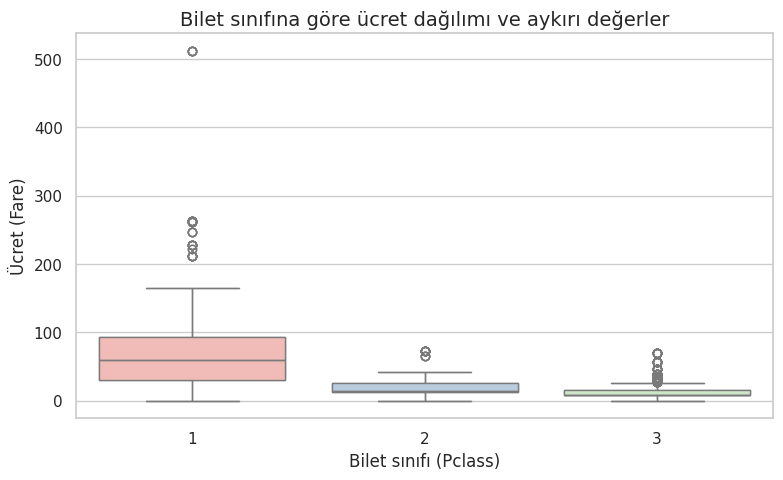

In [ ]:
plt.figure(figsize=(9,5))
sns.boxplot(data=dataset, x="Pclass", y="Fare", palette="Pastel1", showfliers=True)
sns.boxplot(data=dataset, x="Pclass", y="Fare", hue="Pclass", palette="Pastel1", legend=False, showfliers=True)
plt.title("Bilet sınıfına göre ücret dağılımı ve aykırı değerler",fontsize=14)
plt.xlabel("Bilet sınıfı (Pclass)")
plt.ylabel("Ücret (Fare)")
plt.show()

# ----------------------------------------------------------------------
# -RAPOR-
# Bu grafik bize
# --> 1. sınıf bilet ücretlerinde üst sınırın çok üzerinde çok sayıda belirgin aykırı değer (500 üzeri biletler mevcuttur) bulunduğunu,
# --> 2. ve 3. sınıfların medyan ücretleri birbirine oldukça yakın ve alt seviyelerde toplandığını
#anlatıyor.

# -KONTROL SORUSU-
# Bu soruyu cevaplamak için neden bu grafik türünü seçtin?
# Veri dağılımının çeyreklik dilimlerini (Q1, Medyan, Q3) görmek ve aykırı değerleri matematiksel sınırlarıyla
#doğrudan yakalamak için Box Plot en standart grafik türüdür.


6- Yaş, Ücret, Sınıf ve Hayatta Kalma İlişkisi (Scatter Plot)

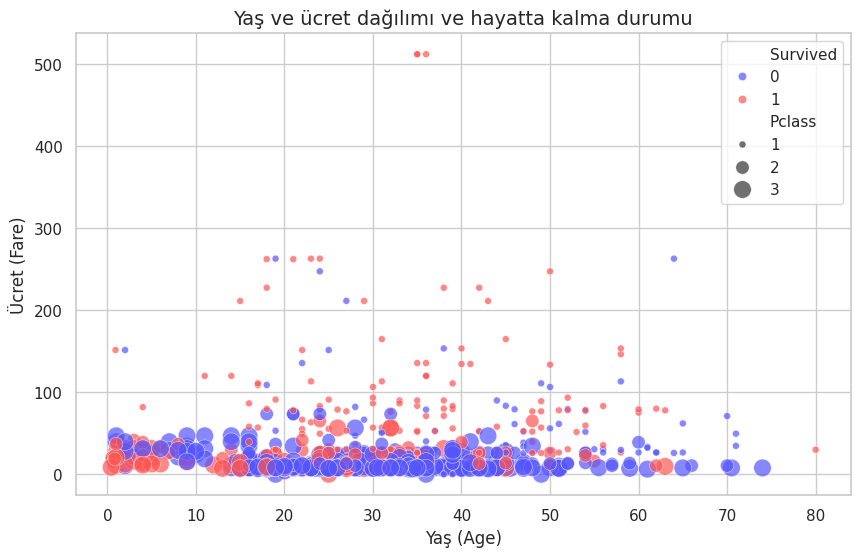

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=dataset,
    x="Age",
    y="Fare",
    hue="Survived",
    size="Pclass",
    sizes=(25,160),
    alpha=0.7,
    palette="seismic",
)
plt.title("Yaş ve ücret dağılımı ve hayatta kalma durumu",fontsize=14)
plt.xlabel("Yaş (Age)")
plt.ylabel("Ücret (Fare)")
plt.show()

# ----------------------------------------------------------------------
# -RAPOR-
# Bu grafik bize
# --> Yaş ile ödenen bilet ücreti arasında belirgin bir doğrusal ilişki yani korelasyon bulunmadığını,
# --> Grafiğin en üst kısmında yer alan ve çok yüksek ücret ödeyen (büyük kırmızı noktalar ve 1. sınıf hayatta kalanlar)
#yolcuların neredeyse tamamının kurtulduğunu,
# --> Düşük ücret ödeyen geniş kalabalıkta (grafiğin taban kısmı) hayatta kalamayanların yoğunlaştığını
#anlatıyor

# -KONTROL SORUSU-
# Bu soruyu cevaplamak için neden bu grafik türünü seçtin?
# İki sürekli sayısal değişken (Age ve Fare) arasındaki ilişkiyi incelerken, aynı anda renk
 #(hue=Survived) ve boyut (size=Pclass) ekleyerek 4 farklı boyutu tek bir düzlemde gözlemleyebilmek
 #için Scatter Plot tercih edildi.


7-Veri Temizleme

TEMİZLEME ÖNCESİ EKSİK DEĞER KONTROLÜ
Age eksik sayısı: 177
Embarked eksik dağılımı:
 Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

TEMİZLEME SONRASI 
Age eksik sayısı: 0
Uygulanan Age medyan değeri: 28.0


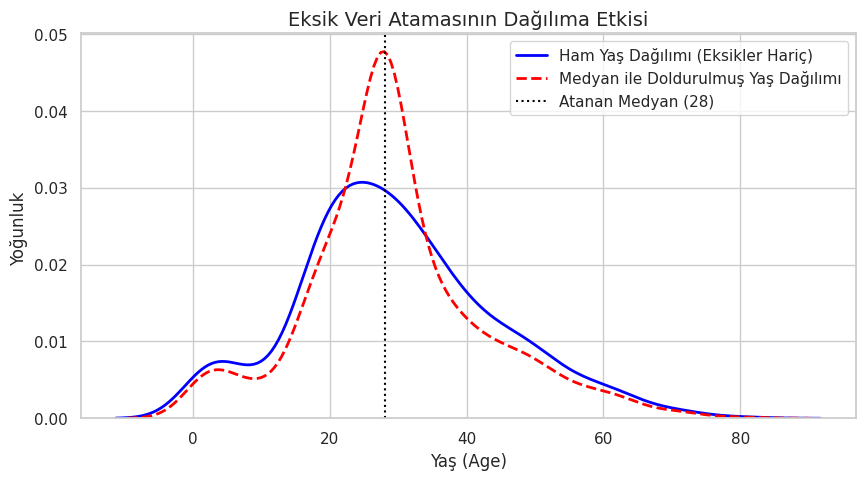

In [ ]:
# Temizleme adımları
print("TEMİZLEME ÖNCESİ EKSİK DEĞER KONTROLÜ")
print("Age eksik sayısı:", dataset["Age"].isnull().sum())
print("Embarked eksik dağılımı:\n", dataset["Embarked"].value_counts(dropna=False))

# Embarked mod ile doldurulur
dataset["Embarked"] = dataset["Embarked"].fillna(dataset["Embarked"].mode()[0])

# Cabin sütunu %77 eksik içerdiği için kaldırma
if "Cabin" in dataset.columns:
    dataset.drop(columns=["Cabin"], inplace=True)

# Yaş sütununu doldurmadan önce ham kopyasını saklayıp karşılaştıralım
age_raw = dataset["Age"].copy()
median_age = dataset["Age"].median()
dataset["Age"] = dataset["Age"].fillna(median_age)

print("\nTEMİZLEME SONRASI ")
print("Age eksik sayısı:", dataset["Age"].isnull().sum())
print("Uygulanan Age medyan değeri:", median_age)

# Doldurma öncesi ve sonrası dağılım değişimi kontrolü
plt.figure(figsize=(10, 5))
sns.kdeplot(age_raw, label="Ham Yaş Dağılımı (Eksikler Hariç)", color="blue", linewidth=2)
sns.kdeplot(dataset["Age"], label="Medyan ile Doldurulmuş Yaş Dağılımı", color="red", linestyle="--", linewidth=2)
plt.axvline(median_age, color="black", linestyle=":", label=f"Atanan Medyan ({median_age:.0f})")
plt.title("Eksik Veri Atamasının Dağılıma Etkisi", fontsize=14)
plt.xlabel("Yaş (Age)")
plt.ylabel("Yoğunluk ")
plt.legend()
plt.show()

# ----------------------------------------------------------------------
# -RAPOR-
# Bu grafik bize:
# --> 177 eksik değer doğrudan medyan (28) ile doldurulduğunda, 28 yaş etrafında yapay bir tepe oluştuğunu,
# --> Verinin doğal varyansının azaldığını ve dağılımın sivrildiğini,
# --> Model kurma aşamasında bu sivrilmenin önüne geçmek için ilerleyen adımlarda 'Pclass' ve 'Sex' gruplarına göre
#     koşullu medyan gibi yöntemlerin değerlendirilmesi gerektiğini
# anlatıyor.

# HAFTA 5: VERİ ANALİZİ VE GÖRSELLEŞTİRME (EDA RAPORU)

### 1. Veri Seti ve Ön Hazırlık Özeti
- **Kaynak ve Boyut:** 891 satır ve 11 sütun (PassengerId indeks) içeren Titanic eğitim verisi incelenmiştir.
- **Hedef Değişken Analizi:** Hayatta kalma oranı %38.4, hayatını kaybeden oranı %61.6 olarak tespit edilmiştir ve sınıf dengesizliği mevcuttur.
- **Temizleme ve Dağılım Etkisi:**
  - Embarked eksikleri en sık geçen değer ('S') ile tamamlanmıştır.
  - %77'si kayıp olan Cabin sütunu çıkarılmıştır.
  - Age sütunundaki 177 eksik değer medyan (28) ile doldurulmuştur. Ancak dağılım kontrol grafiğinde gösterildiği üzere bu işlem 28 yaş bandında yapay bir frekans artışına yol açmıştır.

### 2. Temel Bulgular ve Verinin Hikayesi
- **Cinsiyet ve Sınıf Önceliği:** Hayatta kalmada en belirleyici faktörler bilet sınıfı ve cinsiyettir. 1. sınıf kadın yolcuların %96'dan fazlası kurtulurken, 3. sınıf erkek yolcularda bu oran %13 civarına düşmektedir.
- **Yaş Faktörü:** Ham yaş dağılımında 0-10 yaş grubu çocukların hayatta kalma ihtimali daha yüksektir.
- **Ücret Dağılımı ve Aykırı Değerler:** Bilet ücreti (Fare) aşırı sağa çarpıktır. 1. sınıfta 500 birimi aşan aykırı değerler yer alırken, 2. ve 3. sınıflar düşük ücret aralığında kümelenmiştir. Yüksek ücret ödeyen yolcuların hayatta kalma olasılığı belirgin biçimde yüksektir.